Document findings on model interpretability by conducting a comprehensive case study, integrating qualitative insights from domain experts, and proposing improvements for enhancing explainability in real-world scenarios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target])

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight="balanced", random_state=42
    )
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Model trained successfully.")

Model trained successfully.


In [2]:
metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1 Score": f1_score(y_test, predictions, zero_division=0)
}

metrics_df = pd.DataFrame(
    list(metrics.items()), columns=["Metric", "Score"]
)

print(metrics_df.to_string(index=False))

   Metric    Score
 Accuracy 0.750000
Precision 0.833333
   Recall 0.833333
 F1 Score 0.833333


 Feature  Mean F1 Decrease
     age          0.104464
    chol          0.000812
 oldpeak          0.000000
 thalach         -0.037333
trestbps         -0.037949


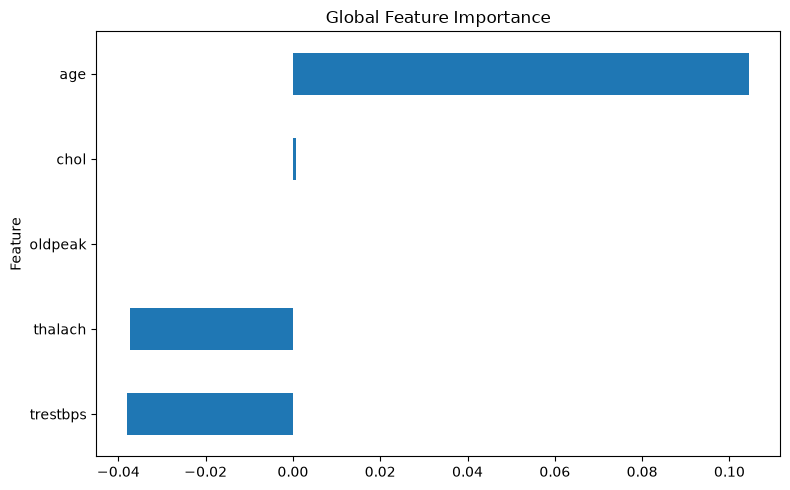

In [3]:
baseline_f1 = f1_score(y_test, predictions)
importance_results = []

for feature in features:
    drops = []

    for seed in range(10):
        shuffled = X_test.copy()
        shuffled[feature] = shuffled[feature].sample(
            frac=1, random_state=seed
        ).to_numpy()

        score = f1_score(
            y_test, model.predict(shuffled), zero_division=0
        )
        drops.append(baseline_f1 - score)

    importance_results.append({
        "Feature": feature,
        "Mean F1 Decrease": np.mean(drops)
    })

importance_df = pd.DataFrame(importance_results).sort_values(
    "Mean F1 Decrease", ascending=False
)

print(importance_df.to_string(index=False))

importance_df.sort_values("Mean F1 Decrease").plot(
    x="Feature", y="Mean F1 Decrease",
    kind="barh", legend=False, figsize=(8, 5),
    title="Global Feature Importance"
)

plt.tight_layout()
plt.show()

In [5]:
patient = X_test.iloc[[0]]
probability = model.predict_proba(patient)[0, 1]
prediction = model.predict(patient)[0]

print("Patient details:")
print(patient.to_string(index=False))
print("Predicted class:", prediction)
print("Probability of class 1:", round(probability, 4))

reference = X_train.median()

local_effects = []

for feature in features:
    changed = patient.copy()
    changed[feature] = reference[feature]

    changed_probability = model.predict_proba(changed)[0, 1]

    local_effects.append({
        "Feature": feature,
        "Patient Value": patient.iloc[0][feature],
        "Probability Change": probability - changed_probability
    })

local_df = pd.DataFrame(local_effects).sort_values(
    "Probability Change", key=abs, ascending=False
)

print(local_df.to_string(index=False))

Patient details:
 age  trestbps  chol  thalach  oldpeak
  31       134   255      174      4.1
Predicted class: 0
Probability of class 1: 0.33
 Feature  Patient Value  Probability Change
     age           31.0               -0.56
trestbps          134.0               -0.15
 thalach          174.0                0.02
    chol          255.0               -0.02
 oldpeak            4.1                0.01


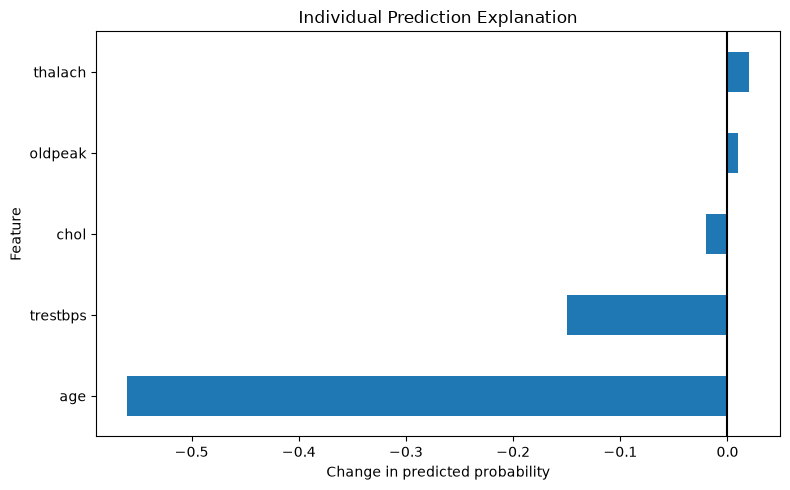

In [6]:
local_df.sort_values("Probability Change").plot(
    x="Feature", y="Probability Change",
    kind="barh", legend=False, figsize=(8, 5),
    title="Individual Prediction Explanation"
)

plt.axvline(0, color="black")
plt.xlabel("Change in predicted probability")
plt.tight_layout()
plt.show()

In [7]:
case_study = {
    "Case": "Heart Disease Prediction Model Interpretability",
    "Model": "Random Forest",
    "Features": ", ".join(features),
    "Model Accuracy": round(metrics["Accuracy"], 4),
    "Model Precision": round(metrics["Precision"], 4),
    "Model Recall": round(metrics["Recall"], 4),
    "Model F1 Score": round(metrics["F1 Score"], 4),
    "Most Important Feature": importance_df.iloc[0]["Feature"],
    "Expert Name/Role": "To be completed after consultation",
    "Expert Feedback": "To be collected from a qualified domain expert",
    "Clinical Agreement": "Pending expert review",
    "Recommended Improvements": "Validate explanations, assess fairness, and test on external data"
}

print(pd.Series(case_study).to_string())

Case                          Heart Disease Prediction Model Interpretability
Model                                                           Random Forest
Features                                age, trestbps, chol, thalach, oldpeak
Model Accuracy                                                           0.75
Model Precision                                                        0.8333
Model Recall                                                           0.8333
Model F1 Score                                                         0.8333
Most Important Feature                                                    age
Expert Name/Role                           To be completed after consultation
Expert Feedback                To be collected from a qualified domain expert
Clinical Agreement                                      Pending expert review
Recommended Improvements    Validate explanations, assess fairness, and te...
